# **Libraries and Dataset**

In [ ]:
!pip install ultralytics opencv-python numpy matplotlib -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 81.3 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
import zipfile
import shutil
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from ultralytics import YOLO
import cv2, numpy as np, yaml, tempfile

In [ ]:
drive.mount('/content/drive')


source_path = '/content/drive/MyDrive/Digital Signal/Kvasir.zip'
destination_path = '/content/dataset.zip'

shutil.copy(source_path, destination_path)
print(f'Copied {source_path} to {destination_path}')


# Unzip the file
with zipfile.ZipFile('/content/dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/data')
print('Extracted dataset.zip to /content/data')

# List contents of the extracted directory to verify
print('Contents of /content/ after extraction:')
print(os.listdir('/content/'))

Mounted at /content/drive
Copied /content/drive/MyDrive/Digital Signal/Kvasir.zip to /content/dataset.zip
Extracted dataset.zip to /content/data
Contents of /content/ after extraction:
['.config', 'data', 'dataset.zip', 'drive', 'sample_data']


## Data

In [ ]:


DATA_YAML  = '/content/data/processed/yolo/kvasir.yaml'   # output of 01_preprocess.py
OUT_DIR    = '/content/data/processed/outputs/yolo'
EPOCHS     = 50
IMGSZ      = 256
BATCH      = 16
PATIENCE   = 10   # early stopping — stop if no mAP gain for this many epochs

Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
print("Ultralytics ready.")

Ultralytics ready.


## Load Pretrained YOLOV8 Model

In [ ]:
model = YOLO('yolov8n.pt')
print(model.info())

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs
(129, 3157200, 0, 8.8575488)


## Train the Model

In [ ]:
results = model.train(
    data         = DATA_YAML,
    epochs       = EPOCHS,
    imgsz        = IMGSZ,
    batch        = BATCH,
    patience     = PATIENCE,
    project      = OUT_DIR,
    name         = 'train',
    pretrained   = True,
    optimizer    = 'AdamW',
    lr0          = 1e-3,
    lrf          = 0.01,        # final LR = lr0 × lrf
    weight_decay = 5e-4,
    warmup_epochs= 3,
    mosaic       = 0.5,
    flipud       = 0.0,         # no vertical flip (endoscopy orientation matters)
    fliplr       = 0.5,
    degrees      = 10.0,
    verbose      = True,
    save         = True,
    plots        = True,
)

best_weights = Path(OUT_DIR) / 'train' / 'weights' / 'best.pt'
print(f"Training complete. Best weights → {best_weights}")

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/processed/yolo/kvasir.yaml, degrees=10.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True

## Test set evaluation

In [ ]:
best_weights = '/content/data/processed/outputs/yolo/train/weights/best.pt'

best_model = YOLO(str(best_weights))

# Patch YAML so val split points to test images
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

cfg_test = cfg.copy()
cfg_test['val'] = cfg_test['test']

with tempfile.NamedTemporaryFile(mode='w', suffix='.yaml', delete=False) as tmp:
    yaml.dump(cfg_test, tmp)
    tmp_yaml = tmp.name

metrics = best_model.val(data=tmp_yaml, imgsz=IMGSZ, split='val', verbose=True)
Path(tmp_yaml).unlink(missing_ok=True)

print(f"\nmAP@0.5      : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.4f}")
print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")

Ultralytics 8.4.60 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 815.8±265.1 MB/s, size: 23.6 KB)
val: Scanning /content/data/processed/yolo/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.5Kit/s 0.1s
val: New cache created: /content/data/processed/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 8.3it/s 1.2s
                   all        150        155      0.926      0.923      0.959      0.756
Speed: 0.5ms preprocess, 4.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val

mAP@0.5      : 0.9590
mAP@0.5:0.95 : 0.7558
Precision    : 0.9264
Recall       : 0.9226


## Sample prediction on the test images

Saved 12 prediction images → /content/data/processed/outputs/yolo/val_predictions/


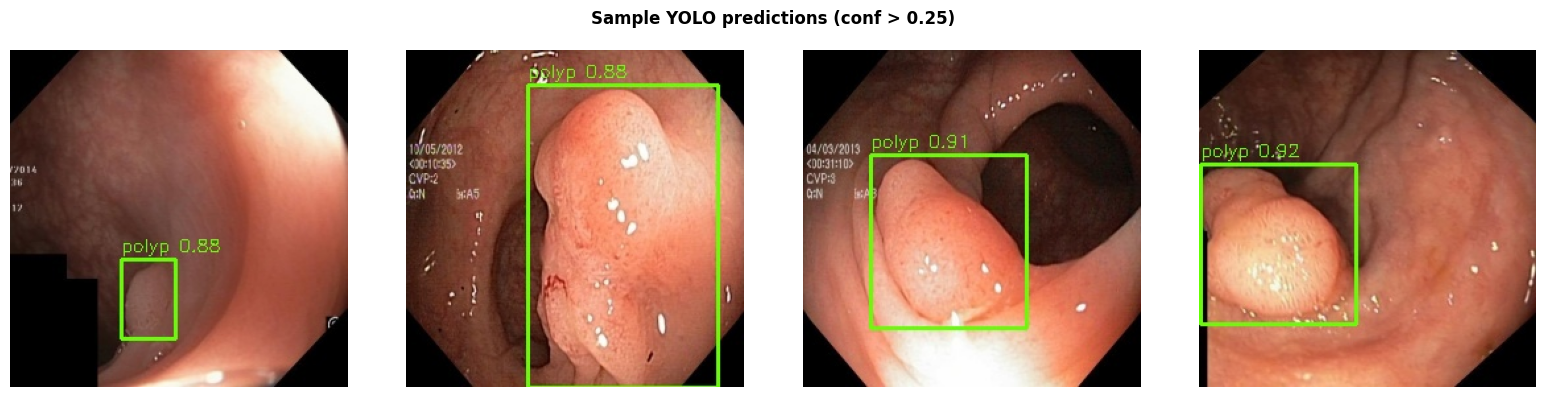

In [ ]:
with open(DATA_YAML) as f:
    data_cfg = yaml.safe_load(f)

base_path    = Path(data_cfg.get('path', '.'))
test_img_dir = base_path / data_cfg.get('test', 'images/test')
test_imgs    = list(test_img_dir.glob('*.jpg'))[:12]

pred_dir = Path(OUT_DIR) / 'val_predictions'
pred_dir.mkdir(exist_ok=True)

if test_imgs:
    preds = best_model.predict(
        source  = [str(p) for p in test_imgs],
        imgsz   = IMGSZ,
        conf    = 0.25,
        save    = False,
        verbose = False,
    )
    for pred, img_path in zip(preds, test_imgs):
        img = cv2.imread(str(img_path))
        for box in pred.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            conf = float(box.conf[0])
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 100), 2)
            cv2.putText(img, f'polyp {conf:.2f}', (x1, max(y1-6, 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 100), 1)
        cv2.imwrite(str(pred_dir / img_path.name), img)
    print(f"Saved {len(test_imgs)} prediction images → {pred_dir}/")

# Display first 4 predictions inline
fig, axes = plt.subplots(1, min(4, len(test_imgs)), figsize=(16, 4))
for ax, img_path in zip(axes, test_imgs[:4]):
    img = cv2.imread(str(pred_dir / img_path.name))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.axis('off')
plt.suptitle('Sample YOLO predictions (conf > 0.25)', fontweight='bold')
plt.tight_layout()
plt.show()